------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


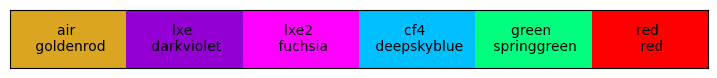

In [18]:
# from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt


from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

from FittingFunctions import *

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi
deg2rad = np.pi/180

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

tOxide dp_star Xpn dw_star pe ph
tOxide dp_star Xpn dw_star pe ph
tOxide dp_star Xpn dw_star pe ph
tOxide dp_star Xpn dw_star pe ph


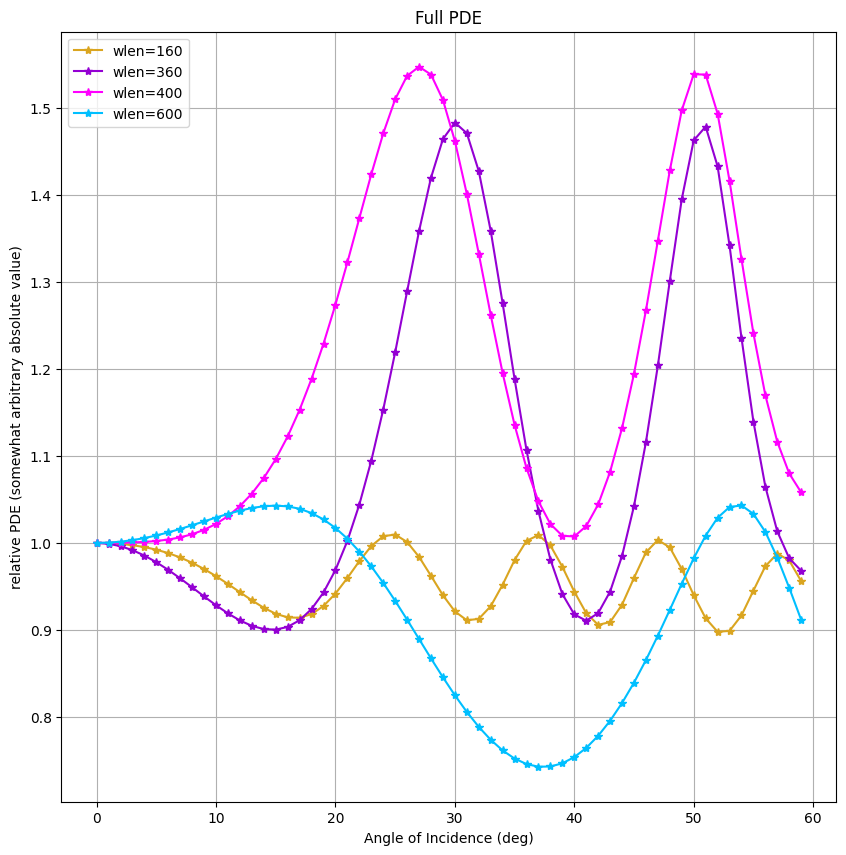

In [19]:
pn = PNJ.PNJunction(tOxide = 1360, dp_star = 1.5, Xpn = 0.32e3, dw_star = 4e3, pe = 0.9, ph = 0.35)
pnDict = {"tOxide":1360, "dp_star":1.5, "Xpn":0.32e3, "dw_star":4.4e3, "pe":0.9, "ph":0.35}

xAngles = np.arange(0, 60, 1)
vlines = [160, 360, 400, 600]
# vlines = [590]
ms.ResetColorCycle()

fig, ax1 = plt.subplots(1, 1, figsize = (10, 10))

# complete PDE
ax1.set_title("Full PDE")
for i, wlen in enumerate(vlines):
    col = ms.GetNextColor()
    photon1 = PhotonInfo(wlen = wlen, theta_1=xAngles)
    
    # PDE = PDE_allArgs(pn, photon1)
    print(*pnDict)
    PDE = PDE_allArgs_Angle(wlen=wlen, theta1=xAngles, **pnDict, FF=0.8, smoothSigma=3/2.335)
    ax1.plot(xAngles, PDE/PDE[0], color = col, marker="*", linestyle="-", label = f"wlen={wlen}") #Xpn:{pn.Xpn/1000} um, dw*:{pn.dw_star/1000} um")
    
    # PDE2 = np.array(FullPDE_fromObjects(pn2, PhotonInfo(wlen = wlen, theta_1=xAngles)))
    # plt.plot(xAngles, PDE2/PDE2[0], color = col, linestyle = "--", label = f"Xpn:{pn2.Xpn/1000} um, dw*:{pn2.dw_star/1000} um")

ax1.grid()
plt.xlabel("Angle of Incidence (deg)")
plt.ylabel("relative PDE (somewhat arbitrary absolute value)")
plt.legend(title=f"", fontsize=10)
plt.show()



In [20]:
from scipy.optimize import minimize

# Your function
def func(x):
    angle, wavelength = x
    # Calculate the function value
    return -1 * (angle * wavelength)  # Replace this with your actual function

# Initial guess
x0 = [0, 0]

# Bounds for angle and wavelength
bounds = [(0, 90), (400, 700)]

# Find the maximum
res = minimize(func, x0, bounds=bounds)

# Print the maximum
print('Maximum:', -res.fun)
print('Angle:', res.x[0])
print('Wavelength:', res.x[1])

Maximum: 63000.0
Angle: 90.0
Wavelength: 700.0


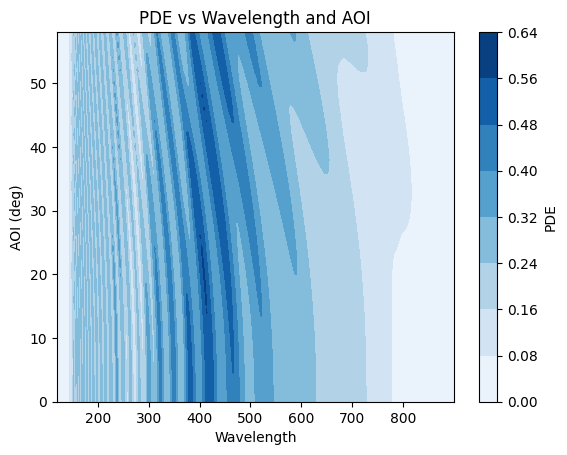

In [21]:
# Define the range of X and Y
X = np.arange(120, 900, 1.0)
Y = np.arange(0, 60, 2)

# Calculate Z
maxT = 0
optAng, optWlen = 0, 0
Z = np.zeros((len(Y), len(X)))
for i, angle in enumerate(Y):
    for j, wavelength in enumerate(X):
        # Calculate Z value based on your calculation
        # Z[i, j] = PhotonInfo(wavelength, angle).Wave_TotalTransmission(pn.tOxide)
        Z[i, j] = PDE_allArgs(wlen=wavelength, theta1=angle, **pnDict, FF=0.8)
        
        # finding maximum
        if Z[i, j] > maxT:
            maxT = Z[i, j]
            optAng = angle
            optWlen = wavelength

# Create a meshgrid for X and Y
X, Y = np.meshgrid(X, Y)

# Create the contour plot
plt.contourf(X, Y, Z, cmap='Blues')

# Set labels and title
plt.xlabel('Wavelength')
plt.ylabel('AOI (deg)')
plt.title('PDE vs Wavelength and AOI')

# Show the plot
plt.colorbar(label='PDE')
plt.show()


In [22]:
print("maxT:", maxT)
print("optAng:", optAng)
print("optWlen:", optWlen)

maxT: 0.5633080495313619
optAng: 20
optWlen: 409.0


---
### Analytic math

* $ff$ - 1D width of a trench (units of $\mu m$)
* $FF$ - Unitless, sensitive area per full pixel
* $p$ - repeatable pixel size (length of entire pixel including surrounding $ff$ on both sides)

We will write out the $FF$ as a ratio of the inner pixel size to the total pixel size

$$ FF = \frac{(p - 2ff)^2}{p^2} $$
$$ 4 ff^2 \mathbf{-4p} ff + p^2 = FF \cdot p^2 $$
$$ 4 ff^2 \mathbf{-4p} ff + \mathbf{(1-FF)p^2} = 0 $$
$$ ff^2 \mathbf{-p} ff + \mathbf{(1-FF)p^2/4} = 0 $$

$$ \mathbf{a}x^2 + \mathbf{b}x + \mathbf{c} = 0$$

If we want to be fancy, and include the small resistor, with area~60um, can add that fraction to FF (or subtract it from the main sensitive rectangle)

$$ FF = \frac{(p - 2ff)^2 - (60um^2)}{p^2} $$

$$ FF + \frac{60um^2}{p^2} = \frac{(p - 2ff)^2}{p^2} $$

The quadratic equation is solved in the code, giving a ff of a few um


---
### Angular shadowing
THIS IS WRONG. I am subtracting the shadowed area both times (quadratically) but only one axis is shadowed
$$ FF(\theta) = \frac{(p - 2ff - h\tan\theta)^2}{p^2} $$
... (commented out)
<!--
$$ \xi \equiv 2ff + h\tan\theta $$
$$ FF(\theta) = \frac{(p - \xi)^2}{p^2} $$
$$ W\equiv \frac{ff}{p}$$
$$ H\equiv \frac{h}{p}$$

$$ FF(\theta) = \frac{p^2 - 2p\xi + \xi^2}{p^2} $$
$$ FF(\theta) = (1 - 2W)^2 + H\tan\theta(H\tan\theta + 4W - 2) $$
-->
---
__Trying correct below__  
$l$ is the length of the shadow. This is the length of the side of the 'shadowing' rectangle:
$$ l = h\tan\theta $$
doing $A_{pixel} = a \times b$:
$$ FF(\theta) = \frac{(p - 2ff)(p-2ff - l)}{p^2} $$
doing $A_{pixel} = A_{full} - A_{shadow}$:
$$ FF(\theta) = \frac{(p - 2ff)^2 - l(p-2ff)}{p^2} $$
both expand (thanks wolfram) to give the same result:
$$ FF(\theta) = \frac{4ff^2 + 2ff \cdot l - 4ff \cdot p - lp + p^2}{p^2} $$

Then subbing in $W\equiv ff/p$ and $H\equiv h/p$, which also includes $\frac{l}{p} \equiv H\tan\theta$ we get:

$$ FF(\theta) = 4W^2 - 4W + 1 - (1-2W)H\tan\theta $$
$$ FF(\theta) = [4W^2 - 4W + 1] - (1-2W)H\tan\theta $$

Using this equation for the quadratic solution with $\theta$ = 0, we have the same thing as above to use in the quadratic equation to solve for $W$:
$$ 0 = W^2 - W + \frac{1-FF}{4} $$

__Reflections:__  
The photons also have to 'bounce out' so the shadowing applies twice, the photons incoming are blocked ($l$) and the outgoing are blocked as well. You can go through all the math to check but:
$$ FF_{Ref}(\theta) = 4W^2 - 4W + 1 - \mathbf{2}(1-2W)H\tan\theta $$

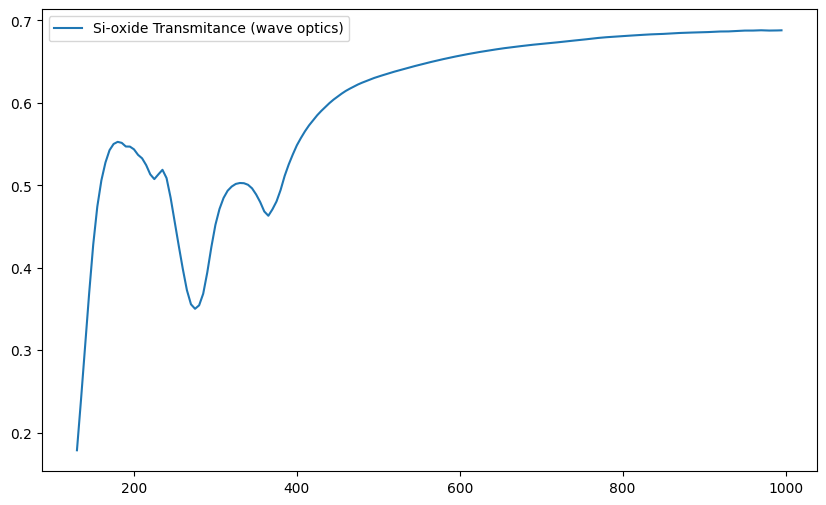

In [23]:
xwlen = np.arange(130, 1000, 5)
# xwlen = [160,180,200,300,380]
ap = PhotonInfo(wlen = xwlen, theta_1=0)
standardPN = PNJunction(tOxide=18.)

Tquartz, Rquartz = ap.T_R_quartzWindow()
Tsi = ap.Wave_TotalTransmission(standardPN)
Rsi = ap.Wave_TotalReflection(standardPN)
Ttotal = ap.T_total_windowAndOxide(standardPN)

# testing result for wave optics
twindow = 0.5 * 1e6 # mm to nm
n1 = ap.nVacuum
n2 = ap.nOxide
theta1=ap.theta_1 # in vacuum
theta2=ap.theta_2 # in quartz
Tquartz_wave = ME.Wave_TwoLayerTransmission_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Rquartz_wave = ME.Wave_TwoLayerReflection_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Ttotal_wave = Tsi*Tquartz_wave/(1-Rquartz_wave*Rsi)

plt.figure(figsize=(10, 6))

# plt.plot(xwlen, Rquartz, label = "Quartz window full Reflectance")
# plt.plot(xwlen, Tquartz, label = "Quartz window Transmitance")

plt.plot(xwlen, Tsi, label = "Si-oxide Transmitance (wave optics)")

# plt.plot(xwlen, Ttotal, label = "Total Transmitance\n(ray optics on window x wave on Si)")

# Ttotal_test = ap.T_total_windowAndOxide(25)
# plt.plot(xwlen, Ttotal_test, label = "Total Transmitance (test, 25nm)")

# plt.plot(xwlen, Ttotal_wave, alpha = 0.3, label = "Total Transmitance (wave optics)")
# plt.plot(xwlen, -0.0 + ap.T_total_windowAndOxide(standardPN), label = "test from photon object")

plt.legend()

# print(xwlen)
# print(Tsi)
print()

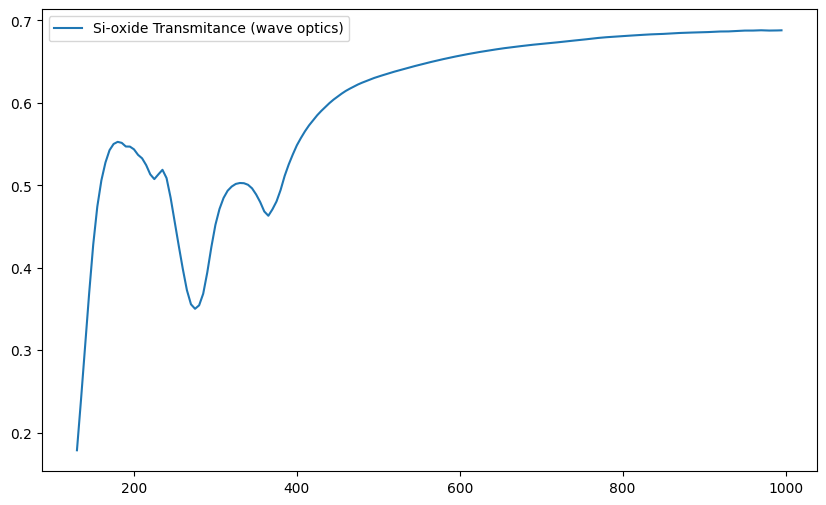

In [24]:
xwlen = np.arange(130, 1000, 5)
# xwlen = [160,180,200,300,380]
ap = PhotonInfo(wlen = xwlen, theta_1=0)
standardPN = PNJunction(tOxide=18.)

Tquartz, Rquartz = ap.T_R_quartzWindow()
Tsi = ap.Wave_TotalTransmission(standardPN)
Rsi = ap.Wave_TotalReflection(standardPN)
Ttotal = ap.T_total_windowAndOxide(standardPN)

# testing result for wave optics
twindow = 0.5 * 1e6 # mm to nm
n1 = ap.nVacuum
n2 = ap.nOxide
theta1=ap.theta_1 # in vacuum
theta2=ap.theta_2 # in quartz
Tquartz_wave = ME.Wave_TwoLayerTransmission_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Rquartz_wave = ME.Wave_TwoLayerReflection_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Ttotal_wave = Tsi*Tquartz_wave/(1-Rquartz_wave*Rsi)

plt.figure(figsize=(10, 6))

# plt.plot(xwlen, Rquartz, label = "Quartz window full Reflectance")
# plt.plot(xwlen, Tquartz, label = "Quartz window Transmitance")

plt.plot(xwlen, Tsi, label = "Si-oxide Transmitance (wave optics)")

# plt.plot(xwlen, Ttotal, label = "Total Transmitance\n(ray optics on window x wave on Si)")

# Ttotal_test = ap.T_total_windowAndOxide(25)
# plt.plot(xwlen, Ttotal_test, label = "Total Transmitance (test, 25nm)")

# plt.plot(xwlen, Ttotal_wave, alpha = 0.3, label = "Total Transmitance (wave optics)")
# plt.plot(xwlen, -0.0 + ap.T_total_windowAndOxide(standardPN), label = "test from photon object")

plt.legend()

# print(xwlen)
# print(Tsi)
print()

In [25]:
def quadraticSolution(a, b, c):
    return np.array([(-b + np.sqrt(b**2 - 4*a*c))/(2*a), (-b - np.sqrt(b**2 - 4*a*c))/(2*a)])

FF = 0.6
p = 50 # units of um
FF2 = 0.7
p2 = 75 # units of um

## Case A
case50_relative = quadraticSolution(a = 1, b = -1, c = (1-FF)/4)

# case75 = quadraticSolution(a = 1, b = -p2, c = (1-FF2)*(p2**2)/4)

case50_absolute = quadraticSolution(a = 1, b = -p, c = (1-FF)*p**2/4)

print("50um pitch, ff: ", case50_relative * p)
print("50um pitch, ff absolute: ", case50_absolute)
# print("75um pitch, ff: ", case75)

50um pitch, ff:  [44.36491673  5.63508327]
50um pitch, ff absolute:  [44.36491673  5.63508327]


In [26]:
# from AFM measurements
p = 50
ffm = 7
Wm = ffm/p
hm = 2.5
Hm = hm/p

# calculated values. need to use this for effective model
ffc = case50_absolute[1]
# Wc = ffc/p
Wc = case50_relative[1]
Hc = hm/p
Hc = 0
print(f'ff side relative to pitch: {Wc*100:.2f}%')
print(f"height relative to pitch: {Hc*100:.2f}%")

print(FF_theta_relative(theta=0, W=Wc, H=0))
# print(FF_theta_absolute(p, ffc, hm, 0))

# xThetas = np.linspace(0, 80, 100)
# ffAbsolute = FF_theta_absolute(p=p, ff=ffc, h=1.5, theta=xThetas)
# ffRelative = FF_theta_relative(W=Wc, H=1.5/p, theta=xThetas)


# plt.plot(xThetas, ffRelative/FF, label = "Relative eqn")
# plt.plot(xThetas, ffAbsolute/FF - 0.01, label = "Absolute eqn, shifted (correct!)")

# plt.legend()
# # plt.xlim(0, 15)
# # plt.ylim(0.5, 0.62)

# plt.grid()
# plt.show()

ff side relative to pitch: 11.27%
height relative to pitch: 0.00%
0.6000000000000001


In [27]:
xBase = 36.4 - 30.66
yBase = 11.95 - 11.7
dBase = np.sqrt(xBase**2 + yBase**2)

xHeight = 32.33 - 30.66
yHeight = 22.66 - 11.95
dHeight = np.sqrt(xHeight**2 + yHeight**2)

resistorArea = dBase * dHeight
print("Resistor area: ", resistorArea)

Resistor area:  62.27724848851303


---
### Single Plane Diffraction

In [28]:
import scipy.special as spec

a = 2 + 0.1j
abs(a)
a**2
a * np.conj(a)

2**2 + 0.1**2

print(spec.fresnel(0))

(0.0, 0.0)


In [29]:
cc = 3e8 * 1e-9 # nm/s
def WaveNumber(wlen): # in units of whatever 1/wlen
    return 2*np.pi/wlen 

def EtaArg(wlen, Z, X):
    k=np.pi*2/wlen
    return np.sqrt(k/(2*Z)) * X #has units of distance

def ParallellKnifeEdge_Intensity(wlen, Z, X):
    arg = EtaArg(wlen, Z, X) * 2/np.pi # now unnormalized argument
    
    a, b = spec.fresnel(arg)
    a += 1/2
    b += 1/2
    
    return 0.5 * (a**2 + b**2)

@np.vectorize
def IntegrateShadow(wlen, Z, Xheight):
    
    epsilonStart = 1e-3
    integratedIntensity = sp.integrate.quad(lambda zFloor: ParallellKnifeEdge_Intensity(wlen=wlen, Z=zFloor, X=Xheight),
                                            a=epsilonStart, b=Z, limit=100)
    return integratedIntensity[0]
# spec.fresnel(1)



Text(0, 0.5, 'Intensity')

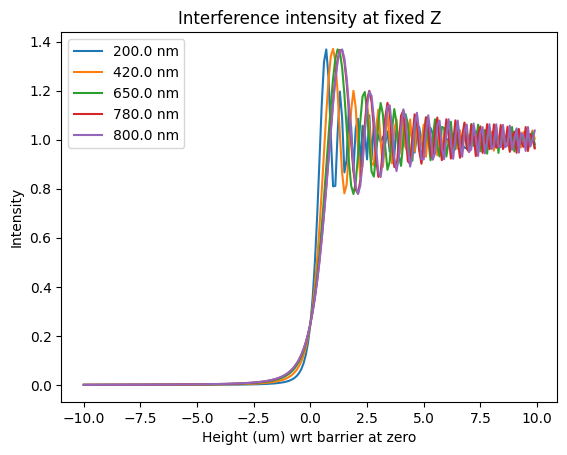

In [30]:
fixedZ_xVals = np.arange(-10, 10, 0.1)
fewWlens = [200e-3, 420e-3, 650e-3, 780e-3, 800e-3]
for wl in fewWlens:
    plt.plot(fixedZ_xVals, ParallellKnifeEdge_Intensity(wl, Z=2, X=fixedZ_xVals), label = f"{wl*1e3} nm")

plt.legend()
plt.title("Interference intensity at fixed Z")
plt.xlabel("Height (um) wrt barrier at zero")
plt.ylabel("Intensity")

Text(0, 0.5, 'Intensity')

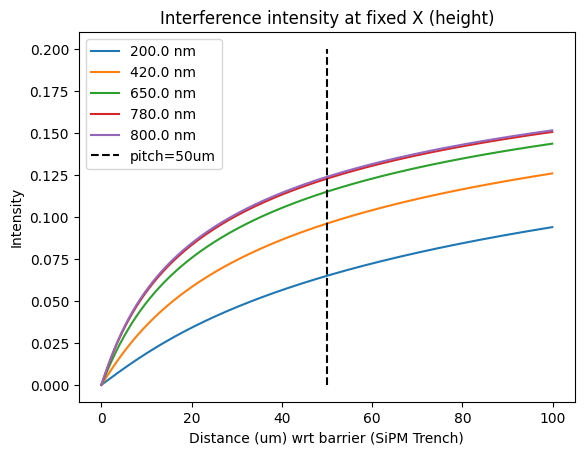

In [31]:
dx = 0.1
fixedX_ZVals = np.arange(1e-3, 100, dx)
wallHeight = 2 # 2 microns high

fewWlens = [200e-3, 420e-3, 650e-3, 780e-3, 800e-3]
for wl in fewWlens:
    y = ParallellKnifeEdge_Intensity(wl, Z=fixedX_ZVals, X=-wallHeight)
    area = sp.integrate.trapz(y, fixedX_ZVals)
    
    # area2 = IntegrateShadow(wlen=wl, Z=max(fixedX_ZVals), Xheight=-wallHeight)
    
    integratedIntensity = sp.integrate.quad(lambda zFloor: ParallellKnifeEdge_Intensity(wlen=wl, Z=zFloor, X=-wallHeight),
                                            a=1e-3, b=max(fixedX_ZVals), limit=100)
    
    plt.plot(fixedX_ZVals, y, label = f"{wl*1e3} nm")

plt.vlines(50, 0, 0.2, linestyle='--', color='black', label = "pitch=50um")
plt.legend()
plt.title("Interference intensity at fixed X (height)")
plt.xlabel("Distance (um) wrt barrier (SiPM Trench)")
plt.ylabel("Intensity")

Text(0.5, 1.0, 'Integrated intensity from 0-50 um at -2um below barrier')

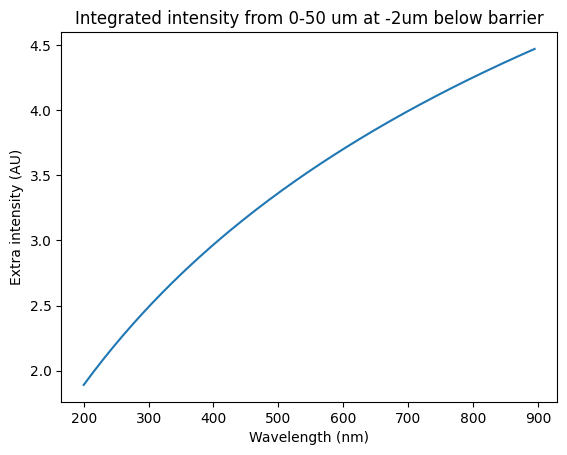

In [32]:
wavelengths = np.arange(200, 900, 5)*1e-3 # in um

pitchSize = 50 # 50 um
extraIntensity = IntegrateShadow(wavelengths, Z=pitchSize, Xheight=-wallHeight)

plt.plot(wavelengths*1e3, extraIntensity)
plt.ylabel("Extra intensity (AU)")
plt.xlabel("Wavelength (nm)")
plt.title(f"Integrated intensity from 0-{pitchSize:0.0f} um at -{wallHeight}um below barrier")

## Estimating for full reflection



photons can reflect off the uphill or 'harsh' side, or the 'soft' downhill side of the resistor. 

There are angular cutoffs for each case.  
We know that for incoming photons on the harsh side
$$ \theta_{incident} = \theta + 2\beta $$

On the soft side, this is flipped:
$$ \theta_{incident} = 2\beta - \theta $$


The effect from reflection is the relative area of the resistor edge, multiplied by R, a dot product for the 'shadow' or angle, and the PDE at the new input angle with FF = 1.0 because we are within a single pixel. I suppose the whole thing should be multiplied by FF but not if we are doing the relative change to PDE

relative area:

$$ A_{rel}(\beta) = \frac{(p - 2ff) * h / \cos\beta}{p^2} $$

<u>Harsh side</u>  
The max incident angle in 90, so the maximum input angle is
$$ \theta_{max} = 90 - 2\beta $$
The dot product in this case, gives when the beam is maximally faxing the resistor edge:

$$PDE_{harsh} = A_{rel}(\beta) \cdot \cos(\theta - \beta) \cdot PDE_{\theta_{incident}}(\theta - \beta)$$


<u>Soft side</u> 

For the soft side, when the beam is angled greater than $\beta$ the beam wont see any of the resistor. The max angle is $\beta$:
$$ \theta_{max} = \beta $$
The dot product in this case, should give zero when the two normal vectors are aligned, so we have to shift by 90 degrees. Another way to think about this is on the opposite edge of the pixel, the resistor is rotated 90 degrees to the 'uphill' one:
$$PDE_{soft} = A_{rel}(\beta) \cdot \cos(\theta - \beta + 90) \cdot PDE_{\theta_{incident}}(2\beta - \theta)$$


The total relative change to the PDE is the sum of the two cases, with some reflectivity $R$. The relative are takes care of the relative change, so this should be the absolute effect.?


$$ PDE_{\text{total}} = PDE_{normal} + R \cdot [PDE_{harsh} + PDE_{soft}] $$

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_37325/3414743108.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


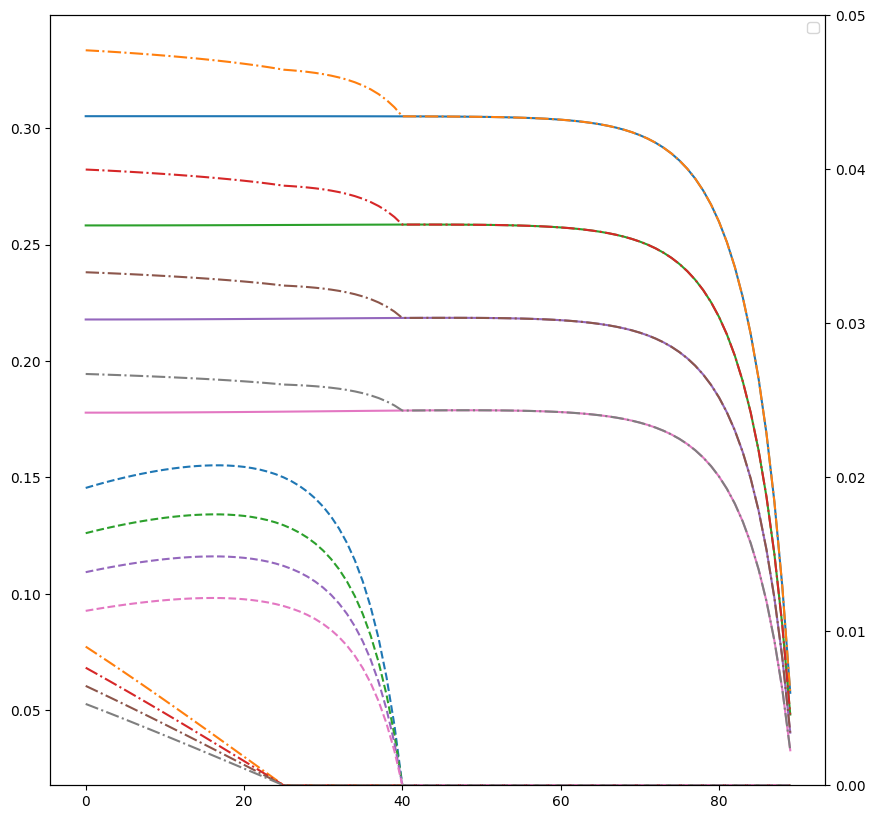

In [108]:


## crazy function

def fullReflection_Harsh(theta, beta, p, ff, h):
    
    relativeArea = (p - 2*ff) * h / np.cos(beta*deg2rad) * np.cos((theta-beta)*deg2rad) / p**2
    
    return relativeArea

def fullReflection_Soft(theta, beta, p, ff, h):
        
        relativeArea = (p - 2*ff) * h / np.cos(beta*deg2rad) * np.cos((theta-beta + 90)*deg2rad) / p**2
        
        return relativeArea

testingRef_anglePN = {"tOxide":17, "dp_star":1.5, "Xpn":2e3, "dw_star":12e3, "pe":0.95, "ph":0.35}

def fullReflection_pde(wlen, theta, beta, p, ff, h):
    
    # photons on more obtuse angles than 90-2beta reflect up the face instead of down
    harsh_inputCut = theta <= 90 - 2*beta
    soft_inputCut = theta <= beta # greater than this and photons miss the soft slope
    
    # print(harsh_inputCut)
    harshSide_angle= theta[harsh_inputCut]+2*beta
    PDE_1 = PDE_allArgs_Angle(wlen=wlen, theta1=harshSide_angle, **testingRef_anglePN, FF=1.0, smoothSigma=None)
    PDE_1 = np.append(PDE_1, np.zeros(np.sum(~harsh_inputCut)))
    
    softSide_angle = 2*beta - theta[soft_inputCut]
    PDE_2 = PDE_allArgs_Angle(wlen=wlen, theta1=softSide_angle, **testingRef_anglePN, FF=1.0, smoothSigma=None)
    PDE_2 = np.append(PDE_2, np.zeros(np.sum(~soft_inputCut)))
    
    harsh = fullReflection_Harsh(theta, beta, p, ff, h) * PDE_1
    soft = fullReflection_Soft(theta, beta, p, ff, h) * PDE_2
    
    return harsh + soft, harsh, soft

beta = 25
xAngles = np.arange(0, 90, 1)

wlens = np.arange(600, 800, 50)

fig, ax1 = plt.subplots(1, 1, figsize = (10, 10))
axt = ax1.twinx()
for wl in wlens:
    t, h, s = fullReflection_pde(wl, xAngles, beta=beta, p=50, ff=6, h=2.5)
    
    PDE_vanilla = PDE_allArgs_Angle(wlen=wl, theta1=xAngles, **testingRef_anglePN, FF=0.6, smoothSigma=3/2.335)
    
    ax1.plot(xAngles, PDE_vanilla, linestyle='-')
    ax1.plot(xAngles, t + PDE_vanilla, linestyle='-.')
    
    # axt.plot(xAngles, t, label = f"{wl} nm", linestyle = "--")
    axt.plot(xAngles, h, linestyle='--')
    axt.plot(xAngles, s, linestyle='-.')
    axt.set_ylim(0, 0.05)
    
plt.legend()